# Species trees: RIDDLE against ASTRAL-IV

The tree-null benchmark (`sptree_eval/`, see its README). `sptree_n200_gt10k_v1` is 50 species trees on 200 taxa with
**no reticulation**, each with 10,000 IQ-TREE gene trees estimated from 1000 bp alignments and rooted on `OUT`. Every
truth is binary, with 198 non-trivial clusters. The ILS axis is the mean internal branch length, **cu 0.1 / 0.25 /
0.5** with 20 / 15 / 15 cells, and **0.1 is the most ILS**. The gene-tree counts are the first 1,000, the first
5,000 and all 10,000 trees of each cell (`SIZES` in the next cell).

**Methods**
- **RIDDLE (k=0)**: `GNN MAP [z+tc]` under the train-fit β, on the relaxed level-1 decoder, with a reticulation budget
  of k = 0. Its output is a tree, often not a binary one.
- **RIDDLE (sweep)**: one network per k sweep, by majority vote. RIDDLE is run at every k = 1..10.
  - A reticulation is its **signature** `(H, {P1∖H, P2∖H})`: the hybrid cluster and the unordered pair of sister
    sets. This is how the fungi events were read (`fungi/scripts/fz_events.py`), with exact matching, since
    simulated taxa have no taxonomy anchors.
  - A signature is **kept** when it is in at least 3 of RIDDLE's 5 networks at k = 1..5.
  - The kept signatures sit on **RIDDLE's own k = 0 tree**: each one adds its hybrid cluster and both parent
    clusters.
  - Built by `sptree_eval/sweep.py`.
- **ASTRAL-IV**: ASTER v1.22.4.6 on the same gene-tree prefixes, rooted on `OUT`.

The truth has no reticulation, so every reticulation RIDDLE keeps is a false one. The sweep keeps 1 to 4 per cell; the
diagnostics table at the end gives the counts.

**Metrics** are scored against the 198 true clusters.
- **Normalised RF** (lower is better): unrooted splits, |Δ| / 2(n − 3) = 394. On a network every hardwired cluster
  counts as a split, so a reticulation's extra clusters count as false splits. On a tree this is collate's
  `rf_norm` exactly (gate W2).
- **Cluster precision, recall and F1** (higher is better): the landed definition, `Instance.cluster_counts`.

**Inputs** (this notebook only reads and draws)

| table | built by |
|---|---|
| `sptree_eval/results/sptree_sweep_rows.csv` | `sptree_eval/sweep.py`: RIDDLE at k = 0..10, RIDDLE sweep and ASTRAL-IV, with the hardwired RF |
| `sptree_eval/results/sptree_sweep_gates.json` | the same; W1–W4 |
| `sptree_eval/results/sptree_gates.json` | `sptree_eval/collate.py --luay` (`LUAY=1 run_sptree.sh collate`); C1–C8 at full counts |
| `sptree_eval/results/sptree_runtime.csv` | `sptree_eval/runtime.py`: seconds per network, per method and cell, with RIDDLE's parts |
| `sptree_eval/results/sptree_runtime_gates.json` | the same; T1–T4 |

Run order: `collate.py`, then `sweep.py` and `runtime.py`, then this notebook. Kernel: `phylo-env`. Figures go to `plots/` as
`sptree-<figure>-ours_l2mix_pair_selF1.png`. Every figure cell sets its own sizes and fonts at the top.

In [1]:
import json
from pathlib import Path

import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

RES_DIR = Path("../sptree_eval/results")
FIG_DIR = Path("../plots")
TAG = "ours_l2mix_pair_selF1"

SIZES = ["1k", "5k", "10k"]     # gene-tree counts drawn
SIZE_LABEL = {"1k": "1,000", "5k": "5,000", "10k": "10,000"}
CUS = [0.1, 0.25, 0.5]          # mean internal branch (CU); 0.1 is the most ILS
CU_CELLS = {0.1: 20, 0.25: 15, 0.5: 15}
RENAME = {"RIDDLE": "RIDDLE (k=0)", "RIDDLE sweep": "RIDDLE (sweep)", "ASTRAL-IV": "ASTER"}
METHODS = ["RIDDLE (k=0)", "RIDDLE (sweep)", "ASTER"]
# RIDDLE's blue is sec3-1's.  ASTRAL-IV takes the dataviz reference palette's slot 2, the one sec3-1 left free:
# validate_palette.js on the pair gives CVD dE 24.7 and normal-vision dE 33.6, both above 3:1 on white.  The sweep
# is RIDDLE's blue tinted toward white, hatched and outlined in a darker blue: sec3-1 Figure 2's mark for "the same
# method, another variant".  The tint alone is under 3:1 on white, so the hatch and the outline carry it, and every
# figure has a legend and a table after it.
BLUE, ORANGE = "#2a78d6", "#eb6834"
TINT, HATCH, DARK = 0.45, "////", 0.6
_rgb = np.array(mcolors.to_rgb(BLUE))
STYLE = {"RIDDLE (k=0)": dict(face=BLUE, line="#333333", hatch=None),
         "RIDDLE (sweep)": dict(face=tuple(1 - TINT * (1 - _rgb)), line=tuple(DARK * _rgb), hatch=HATCH),
         "ASTER": dict(face=ORANGE, line="#333333", hatch=None)}
METRICS = [("rf_hw_norm", "Norm. RF", "lower"),
           ("precision", "Cluster precision", "higher"),
           ("recall", "Cluster recall", "higher"),
           ("f1", "Cluster F1", "higher")]
EDGE, INK, MUTED, GRID = "#333333", "#52514e", "#898781", "#e6e5e0"
N_BOOT = 1000
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
                     "hatch.linewidth": 0.7, "savefig.dpi": 300})
FIG_DIR.mkdir(exist_ok=True)

In [2]:
# Both gate files must be clean, and collate's must come from the full run: --partial relaxes C1's counts, which the
# coverage asserts below would then check only for the sizes drawn here.
g = json.loads((RES_DIR / "sptree_gates.json").read_text())
assert all(v["ok"] for v in g["gates"].values()), {k: v["first"][:3] for k, v in g["gates"].items() if not v["ok"]}
assert not g["partial"], "sptree_gates.json is from collate --partial"
g = json.loads((RES_DIR / "sptree_sweep_gates.json").read_text())
assert all(v["ok"] for v in g["gates"].values()), {k: v["first"][:3] for k, v in g["gates"].items() if not v["ok"]}
VOTE_KS, MIN_VOTES = g["vote_ks"], g["min_votes"]
assert (VOTE_KS, MIN_VOTES) == ([1, 2, 3, 4, 5], 3), (VOTE_KS, MIN_VOTES)

ROWS = pd.read_csv(RES_DIR / "sptree_sweep_rows.csv")
ROWS = ROWS[ROWS["size"].isin(SIZES)].copy()
assert set(ROWS.cu) == set(CUS)

# HEAD: the headline methods, one row per (gene trees, cell, method).  KS: RIDDLE at every k.
HEAD = ROWS[(ROWS.method != "RIDDLE") | (ROWS.k == 0)].copy()
HEAD["method"] = HEAD.method.map(RENAME)
KS = ROWS[ROWS.method == "RIDDLE"].copy()
KS["k"] = KS.k.astype(int)
assert not HEAD.duplicated(["size", "rep", "method"]).any() and not KS.duplicated(["size", "rep", "k"]).any()

# every (gene trees, cu) has every method on every cell, and RIDDLE every k
cov = HEAD.groupby(["size", "cu", "method"]).rep.nunique().unstack("method").reindex(columns=METHODS)
for (size, cu), row in cov.iterrows():
    assert (row == CU_CELLS[cu]).all(), (size, cu, row.to_dict())
kc = KS.groupby(["size", "cu", "k"]).rep.nunique()
assert all(n == CU_CELLS[cu] for (_, cu, _), n in kc.items()) and set(KS.k) == set(range(11))
cov.reindex(SIZES, level="size")

method     RIDDLE (k=0)  RIDDLE (sweep)  ASTER
size cu                                       
1k   0.10            20              20     20
     0.25            15              15     15
     0.50            15              15     15
5k   0.10            20              20     20
     0.25            15              15     15
     0.50            15              15     15
10k  0.10            20              20     20
     0.25            15              15     15
     0.50            15              15     15

## Figure 1: RIDDLE (k=0), RIDDLE (sweep) and ASTRAL-IV

Rows are metrics and columns are ILS levels. Within each panel the x axis is the number of gene trees, and colour is
the method; the sweep is RIDDLE's blue, tinted and hatched.
- **Boxes** show the median and quartiles, with whiskers at 1.5 IQR.
- The **white diamond** is the mean.
- **Grey points** are cells, every one of them (15 or 20 per box).

The y axis is shared along each row. Normalised RF runs over [0, 0.25]; cluster precision, recall and F1
share [0.75, 1]. `YLIM` changes either per metric.

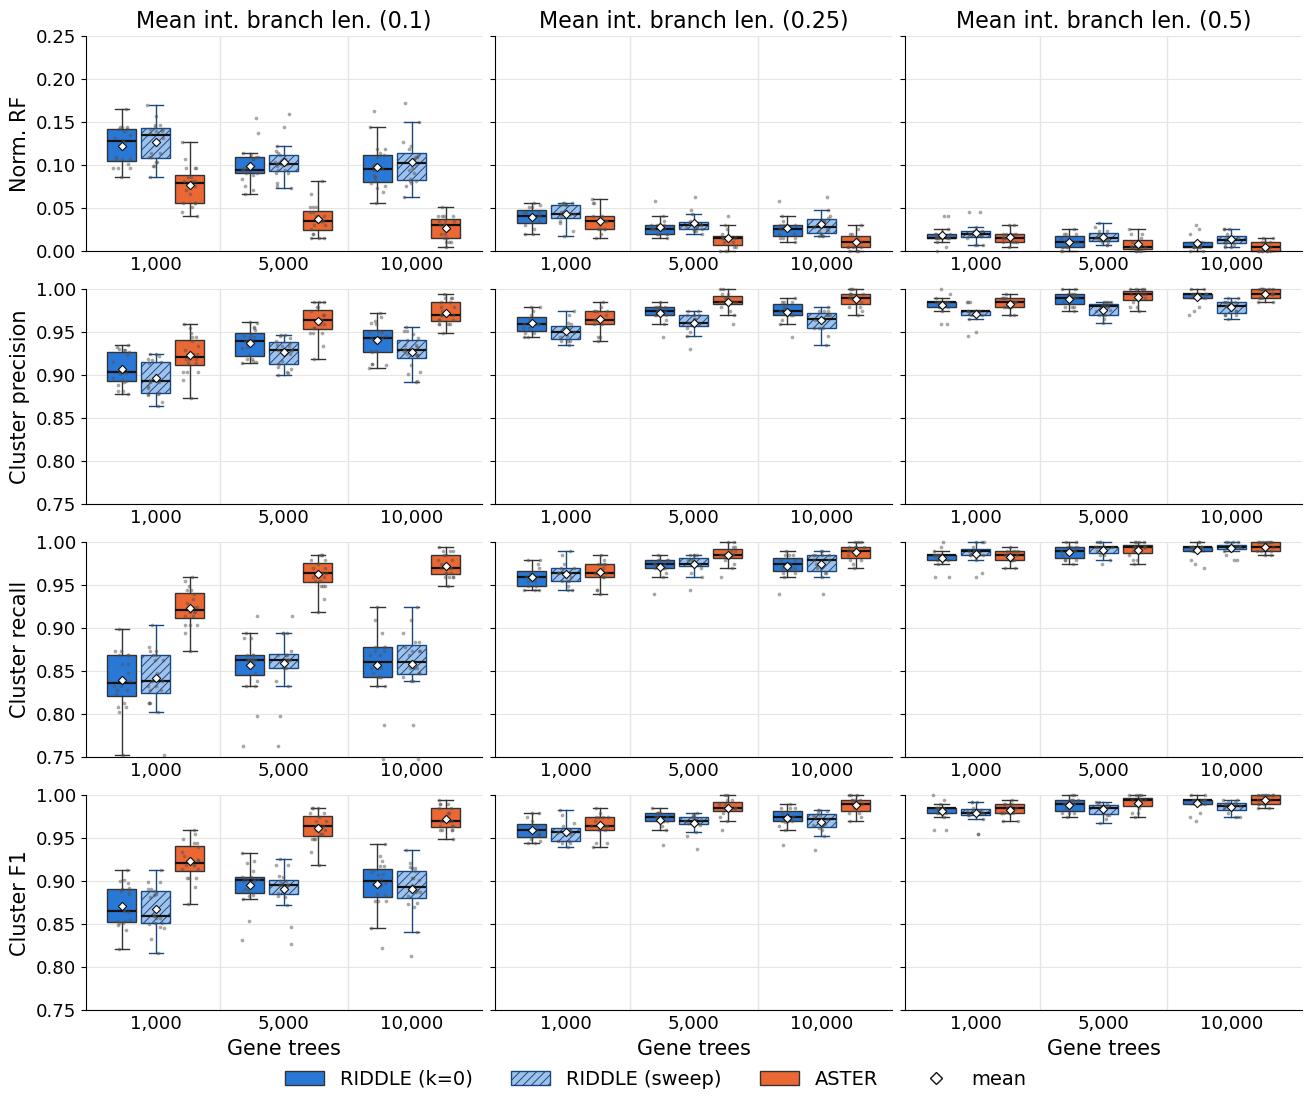

In [3]:
FIGSIZE = (13, 11)
TITLE_FS, LABEL_FS, TICK_FS, LEGEND_FS = 16, 15, 13, 14
YLIM = {"rf_hw_norm": (0, 0.25), "precision": (0.75, 1.0), "recall": (0.75, 1.0),
        "f1": (0.75, 1.0)}   # (lo, hi) per metric
GROUP_W = 0.8           # the width one gene-tree count's boxes share
rng1 = np.random.default_rng(20261029)

step = GROUP_W / len(METHODS)
fig, axes = plt.subplots(len(METRICS), len(CUS), figsize=FIGSIZE, sharey="row", squeeze=False,
                         layout="constrained")
for i, (col, lab, better) in enumerate(METRICS):
    for j, cu in enumerate(CUS):
        ax = axes[i, j]
        for x, size in enumerate(SIZES):
            for s, m in enumerate(METHODS):
                v = HEAD.loc[(HEAD["size"] == size) & (HEAD.cu == cu) & (HEAD.method == m), col].dropna().to_numpy()
                if len(v) == 0:
                    continue
                pos = x + (s - (len(METHODS) - 1) / 2) * step
                st = STYLE[m]
                bp = ax.boxplot([v], positions=[pos], widths=0.85 * step, patch_artist=True, showfliers=False,
                                medianprops=dict(color="#111111", lw=1.6),
                                whiskerprops=dict(color=st["line"], lw=1), capprops=dict(color=st["line"], lw=1))
                bp["boxes"][0].set(facecolor=st["face"], edgecolor=st["line"], linewidth=1, hatch=st["hatch"])
                for artist in bp["boxes"] + bp["whiskers"] + bp["caps"] + bp["medians"]:
                    artist.set_clip_on(False)
                ax.scatter(pos + rng1.uniform(-0.25, 0.25, len(v)) * step, v, s=7, color=INK, alpha=0.5, lw=0,
                           zorder=3, clip_on=False)
                ax.scatter([pos], [v.mean()], marker="D", s=18, color="white", edgecolor="#111111", lw=0.8,
                           zorder=4, clip_on=False)
        ax.set_xticks(range(len(SIZES)))
        ax.set_xticklabels([SIZE_LABEL[s] for s in SIZES], fontsize=TICK_FS)
        ax.set_xlim(-0.55, len(SIZES) - 0.45)
        ax.tick_params(axis="x", length=0)
        ax.tick_params(axis="y", labelsize=TICK_FS)
        ax.grid(axis="y", color=GRID, lw=0.8)
        for x in range(len(SIZES) - 1):
            ax.axvline(x + 0.5, color=GRID, lw=1)
        if i == 0:
            ax.set_title(f"Mean int. branch len. ({cu})", fontsize=TITLE_FS)
        if i == len(METRICS) - 1:
            ax.set_xlabel("Gene trees", fontsize=LABEL_FS)
        if j == 0:
            ax.set_ylabel(lab, fontsize=LABEL_FS)
    if YLIM[col] is not None:
        axes[i, 0].set_ylim(*YLIM[col])

handles = [Patch(facecolor=STYLE[m]["face"], edgecolor=STYLE[m]["line"], hatch=STYLE[m]["hatch"], label=m)
           for m in METHODS]
handles.append(Line2D([], [], marker="D", ls="", color="white", markeredgecolor="#111111", markersize=6, label="mean"))
fig.legend(handles=handles, loc="outside lower center", ncol=len(handles), fontsize=LEGEND_FS, frameon=False)
fig.savefig(FIG_DIR / f"sptree-headline-{TAG}.png", bbox_inches="tight", dpi=300)
plt.show()

In [4]:
# The numbers behind Figure 1: median and mean per gene-tree count, cu and method; cu "all" pools the 50 cells.
rows = []
for size in SIZES:
    for cu in CUS + ["all"]:
        for m in METHODS:
            S = HEAD[(HEAD["size"] == size) & (HEAD.method == m) & ((HEAD.cu == cu) if cu != "all" else True)]
            row = {"gene trees": SIZE_LABEL[size], "cu": cu, "method": m, "cells": len(S)}
            for col, lab, _ in METRICS:
                row[f"{lab} median"] = S[col].median()
                row[f"{lab} mean"] = S[col].mean()
            rows.append(row)
with pd.option_context("display.max_rows", 100, "display.max_columns", 20):
    display(pd.DataFrame(rows).set_index(["gene trees", "cu", "method"]).round(4))

cells  Norm. RF median  Norm. RF mean  \
gene trees cu   method                                                  
1,000      0.1  RIDDLE (k=0)       20           0.1282         0.1226   
                RIDDLE (sweep)     20           0.1345         0.1269   
                ASTER              20           0.0787         0.0766   
           0.25 RIDDLE (k=0)       15           0.0406         0.0401   
                RIDDLE (sweep)     15           0.0431         0.0428   
                ASTER              15           0.0355         0.0352   
           0.5  RIDDLE (k=0)       15           0.0152         0.0183   
                RIDDLE (sweep)     15           0.0203         0.0212   
                ASTER              15           0.0152         0.0169   
           all  RIDDLE (k=0)       50           0.0457         0.0665   
                RIDDLE (sweep)     50           0.0495         0.0699   
                ASTER              50           0.0381         0.0463   
5,000      0.1  RIDDLE (k=0)       20           0.0939         0.0995   
                RIDDLE (sweep)     20           0.1015         0.1042   
                ASTER              20           0.0355         0.0376   
           0.25 RIDDLE (k=0)       15           0.0254         0.0283   
                RIDDLE (sweep)     15           0.0305         0.0328   
                ASTER              15           0.0152         0.0149   
           0.5  RIDDLE (k=0)       15           0.0102         0.0108   
                RIDDLE (sweep)     15           0.0152         0.0164   
                ASTER              15           0.0051         0.0085   
           all  RIDDLE (k=0)       50           0.0305         0.0515   
                RIDDLE (sweep)     50           0.0330         0.0564   
                ASTER              50           0.0152         0.0220   
10,000     0.1  RIDDLE (k=0)       20           0.0952         0.0984   
                RIDDLE (sweep)     20           0.1028         0.1039   
                ASTER              20           0.0305         0.0272   
           0.25 RIDDLE (k=0)       15           0.0254         0.0269   
                RIDDLE (sweep)     15           0.0279         0.0311   
                ASTER              15           0.0102         0.0108   
           0.5  RIDDLE (k=0)       15           0.0051         0.0095   
                RIDDLE (sweep)     15           0.0127         0.0139   
                ASTER              15           0.0051         0.0051   
           all  RIDDLE (k=0)       50           0.0305         0.0503   
                RIDDLE (sweep)     50           0.0355         0.0551   
                ASTER              50           0.0102         0.0156   

                                Cluster precision median  \
gene trees cu   method                                     
1,000      0.1  RIDDLE (k=0)                      0.9035   
                RIDDLE (sweep)                    0.8934   
                ASTER                             0.9217   
           0.25 RIDDLE (k=0)                      0.9596   
                RIDDLE (sweep)                    0.9502   
                ASTER                             0.9646   
           0.5  RIDDLE (k=0)                      0.9848   
                RIDDLE (sweep)                    0.9750   
                ASTER                             0.9848   
           all  RIDDLE (k=0)                      0.9545   
                RIDDLE (sweep)                    0.9450   
                ASTER                             0.9621   
5,000      0.1  RIDDLE (k=0)                      0.9397   
                RIDDLE (sweep)                    0.9293   
                ASTER                             0.9646   
           0.25 RIDDLE (k=0)                      0.9747   
                RIDDLE (sweep)                    0.9604   
                ASTER                             0.9848   
           0.5  RIDDLE (k=0)                      0.9899 

## Figure 2: RIDDLE across the reticulation budget k

Rows are metrics and columns are ILS levels; the x axis is RIDDLE's budget k. The truth has no reticulation, so
every k > 0 adds only false reticulations.
- Each point is the mean over cells, with a 95% cell-bootstrap interval. One line per gene-tree count, bolder with more
  trees: 1,000 is pale with open markers and a dashed line, 5,000 has half-filled markers and a dash-dot line, and
  10,000 is solid with filled markers.
- **sweep**, past the dotted divider, is RIDDLE (sweep), with the same mark per gene-tree count.
- The **grey band** is the vote window, k = 1..5.
- **Orange lines** are ASTRAL-IV's mean per gene-tree count, with the same dash rule.

The y axis is shared along each row; `YLIM` overrides it as in Figure 1.

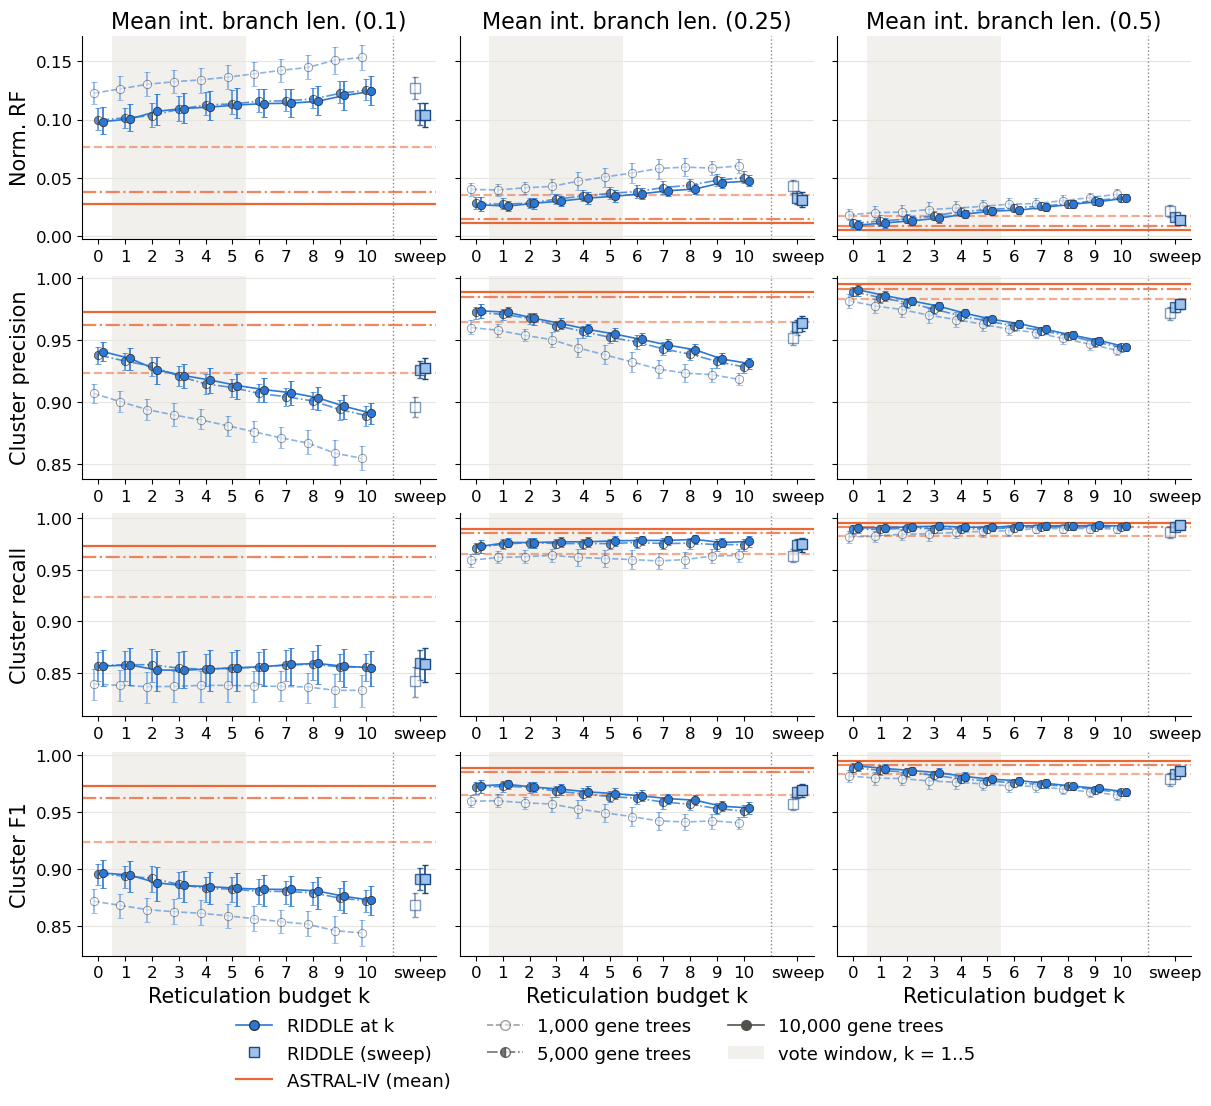

In [5]:
FIGSIZE = (12, 11)
TITLE_FS, LABEL_FS, TICK_FS, LEGEND_FS = 16, 15, 12, 13
YLIM = {"rf_hw_norm": None, "precision": None, "recall": None, "f1": None}
SHOW_ASTRAL, SHOW_SWEEP, SHOW_VOTE_BAND = True, True, True
MS, DODGE = 6, 0.18
# per gene-tree count: opacity, marker fill ("open", "half" or "full") and line style; bolder with more trees
SIZE_STYLE = {"1k": dict(alpha=0.55, fill="open", ls="--"),
              "5k": dict(alpha=0.8, fill="half", ls="-."),
              "10k": dict(alpha=1.0, fill="full", ls="-")}
K_ORDER = list(range(11))
X_SWEEP = len(K_ORDER) + 1          # the sweep's slot, one gap past k = 10
rng2 = np.random.default_rng(20261030)


def fill(ss, face):
    """Marker-face kwargs for a gene-tree count's fill, in colour ``face``."""
    return {"open": dict(mfc="white"), "half": dict(mfc=face, fillstyle="left", markerfacecoloralt="white"),
            "full": dict(mfc=face)}[ss["fill"]]


def boot(v):
    bs = rng2.choice(v, size=(N_BOOT, len(v)), replace=True).mean(axis=1)
    return v.mean(), *np.percentile(bs, [2.5, 97.5])


KSTAT = []
fig, axes = plt.subplots(len(METRICS), len(CUS), figsize=FIGSIZE, sharey="row", squeeze=False,
                         layout="constrained")
for i, (col, lab, better) in enumerate(METRICS):
    for j, cu in enumerate(CUS):
        ax = axes[i, j]
        if SHOW_VOTE_BAND:
            ax.axvspan(min(VOTE_KS) - 0.5, max(VOTE_KS) + 0.5, color="#f1f0ec", lw=0, zorder=0)
        for t, size in enumerate(SIZES):
            ss = SIZE_STYLE[size]
            off = (t - (len(SIZES) - 1) / 2) * DODGE
            stats = []
            for k in K_ORDER:
                v = KS.loc[(KS["size"] == size) & (KS.cu == cu) & (KS.k == k), col].dropna().to_numpy()
                stats.append(boot(v))
                KSTAT.append({"gene trees": SIZE_LABEL[size], "cu": cu, "k": str(k), "metric": lab,
                              "cells": len(v), "mean": stats[-1][0], "lo": stats[-1][1], "hi": stats[-1][2]})
            mu, lo, hi = map(np.array, zip(*stats))
            xs = np.array(K_ORDER) + off
            ax.plot(xs, mu, color=BLUE, lw=1.2, ls=ss["ls"], alpha=ss["alpha"])
            ax.errorbar(xs, mu, yerr=[mu - lo, hi - mu], fmt="o", color=BLUE, ms=MS, mec=EDGE, mew=0.6,
                        **fill(ss, BLUE), capsize=2, lw=1.2, ls="none", alpha=ss["alpha"])
            if SHOW_SWEEP:
                S = HEAD.loc[(HEAD["size"] == size) & (HEAD.cu == cu) & (HEAD.method == "RIDDLE (sweep)"), col]
                m, l, h = boot(S.dropna().to_numpy())
                KSTAT.append({"gene trees": SIZE_LABEL[size], "cu": cu, "k": "sweep", "metric": lab,
                              "cells": S.notna().sum(), "mean": m, "lo": l, "hi": h})
                st = STYLE["RIDDLE (sweep)"]
                ax.errorbar([X_SWEEP + off], [m], yerr=[[m - l], [h - m]], fmt="s", color=st["line"], ms=MS + 1,
                            mec=st["line"], mew=1, **fill(ss, st["face"]), capsize=2, lw=1.2,
                            alpha=ss["alpha"])
            if SHOW_ASTRAL:
                a = HEAD.loc[(HEAD["size"] == size) & (HEAD.cu == cu) & (HEAD.method == "ASTER"), col].mean()
                ax.axhline(a, color=ORANGE, lw=1.6, ls=ss["ls"], alpha=ss["alpha"], zorder=1)
        ticks = K_ORDER + ([X_SWEEP] if SHOW_SWEEP else [])
        ax.set_xticks(ticks)
        ax.set_xticklabels([str(k) for k in K_ORDER] + (["sweep"] if SHOW_SWEEP else []), fontsize=TICK_FS)
        if SHOW_SWEEP:
            ax.axvline(len(K_ORDER), color=MUTED, lw=1, ls=":")
        ax.set_xlim(-0.6, (X_SWEEP if SHOW_SWEEP else K_ORDER[-1]) + 0.6)
        ax.tick_params(axis="y", labelsize=TICK_FS)
        ax.grid(axis="y", color=GRID, lw=0.8)
        if i == 0:
            ax.set_title(f"Mean int. branch len. ({cu})", fontsize=TITLE_FS)
        if i == len(METRICS) - 1:
            ax.set_xlabel("Reticulation budget k", fontsize=LABEL_FS)
        if j == 0:
            ax.set_ylabel(lab, fontsize=LABEL_FS)
    if YLIM[col] is not None:
        axes[i, 0].set_ylim(*YLIM[col])

st = STYLE["RIDDLE (sweep)"]
handles = [Line2D([], [], marker="o", color=BLUE, mec=EDGE, ms=7, lw=1.2, label="RIDDLE at k"),
           Line2D([], [], marker="s", ls="", color=st["line"], mfc=st["face"], ms=7, label="RIDDLE (sweep)"),
           Line2D([], [], color=ORANGE, lw=1.6, label="ASTRAL-IV (mean)")]
handles += [Line2D([], [], marker="o", color=INK, mec=INK, **fill(SIZE_STYLE[s], INK), ls=SIZE_STYLE[s]["ls"],
                   alpha=SIZE_STYLE[s]["alpha"], ms=7, lw=1.2, label=f"{SIZE_LABEL[s]} gene trees") for s in SIZES]
if SHOW_VOTE_BAND:
    handles.append(Patch(facecolor="#f1f0ec", edgecolor="none", label=f"vote window, k = {min(VOTE_KS)}..{max(VOTE_KS)}"))
fig.legend(handles=handles, loc="outside lower center", ncol=3, fontsize=LEGEND_FS, frameon=False)
fig.savefig(FIG_DIR / f"sptree-ksweep-{TAG}.png", bbox_inches="tight", dpi=300)
plt.show()

In [6]:
# The numbers behind Figure 2: mean and 95% cell-bootstrap interval per gene-tree count, cu, k and metric.
K = pd.DataFrame(KSTAT)
K["mean [lo, hi]"] = [f"{m:.4f} [{l:.4f}, {h:.4f}]" for m, l, h in zip(K["mean"], K.lo, K.hi)]
with pd.option_context("display.max_rows", 200, "display.max_columns", 20):
    display(K.pivot_table(index=["gene trees", "cu", "k"], columns="metric", values="mean [lo, hi]", aggfunc="first",
                          sort=False)[[lab for _, lab, _ in METRICS]])

metric                                Norm. RF        Cluster precision  \
gene trees cu   k                                                         
1,000      0.10 0      0.1226 [0.1131, 0.1322]  0.9072 [0.8996, 0.9152]   
                1      0.1264 [0.1169, 0.1371]  0.9006 [0.8926, 0.9094]   
                2      0.1303 [0.1204, 0.1407]  0.8942 [0.8857, 0.9030]   
                3      0.1325 [0.1225, 0.1426]  0.8898 [0.8814, 0.8991]   
                4      0.1341 [0.1231, 0.1447]  0.8859 [0.8782, 0.8947]   
                5      0.1364 [0.1264, 0.1464]  0.8812 [0.8728, 0.8893]   
                6      0.1393 [0.1291, 0.1496]  0.8762 [0.8681, 0.8849]   
                7      0.1423 [0.1325, 0.1517]  0.8714 [0.8635, 0.8801]   
                8      0.1448 [0.1345, 0.1551]  0.8672 [0.8587, 0.8777]   
                9      0.1510 [0.1393, 0.1619]  0.8591 [0.8494, 0.8694]   
                10     0.1533 [0.1423, 0.1642]  0.8550 [0.8457, 0.8650]   
                sweep  0.1269 [0.1173, 0.1368]  0.8966 [0.8882, 0.9044]   
           0.25 0      0.0401 [0.0340, 0.0453]  0.9602 [0.9548, 0.9660]   
                1      0.0396 [0.0340, 0.0447]  0.9581 [0.9528, 0.9634]   
                2      0.0415 [0.0359, 0.0465]  0.9539 [0.9492, 0.9593]   
                3      0.0426 [0.0360, 0.0492]  0.9505 [0.9445, 0.9565]   
                4      0.0472 [0.0396, 0.0547]  0.9438 [0.9368, 0.9517]   
                5      0.0508 [0.0425, 0.0589]  0.9382 [0.9309, 0.9458]   
                6      0.0541 [0.0452, 0.0624]  0.9326 [0.9245, 0.9409]   
                7      0.0580 [0.0494, 0.0662]  0.9267 [0.9193, 0.9340]   
                8      0.0592 [0.0518, 0.0668]  0.9235 [0.9167, 0.9307]   
                9      0.0584 [0.0523, 0.0646]  0.9223 [0.9167, 0.9279]   
                10     0.0602 [0.0545, 0.0658]  0.9185 [0.9136, 0.9233]   
                sweep  0.0428 [0.0367, 0.0481]  0.9517 [0.9462, 0.9573]   
           0.50 0      0.0183 [0.0135, 0.0237]  0.9818 [0.9758, 0.9869]   
                1      0.0201 [0.0147, 0.0262]  0.9776 [0.9719, 0.9829]   
                2      0.0206 [0.0149, 0.0267]  0.9747 [0.9683, 0.9803]   
                3      0.0228 [0.0168, 0.0289]  0.9701 [0.9642, 0.9758]   
                4      0.0240 [0.0186, 0.0301]  0.9667 [0.9604, 0.9726]   
                5      0.0255 [0.0205, 0.0313]  0.9629 [0.9576, 0.9678]   
                6      0.0274 [0.0223, 0.0325]  0.9588 [0.9539, 0.9637]   
                7      0.0279 [0.0235, 0.0327]  0.9561 [0.9519, 0.9600]   
                8      0.0305 [0.0264, 0.0352]  0.9515 [0.9469, 0.9557]   
                9      0.0330 [0.0289, 0.0374]  0.9469 [0.9424, 0.9510]   
                10     0.0359 [0.0318, 0.0403]  0.9420 [0.9378, 0.9455]   
                sweep  0.0212 [0.0161, 0.0269]  0.9718 [0.9662, 0.9771]   
5,000      0.10 0      0.0995 [0.0911, 0.1099]  0.9381 [0.9308, 0.9446]   
                1      0.1015 [0.0929, 0.1103]  0.9332 [0.9264, 0.9399]   
                2      0.1034 [0.0938, 0.1146]  0.9290 [0.9214, 0.9366]   
                3      0.1089 [0.0991, 0.1206]  0.9212 [0.9132, 0.9290]   
                4      0.1126 [0.1038, 0.1241]  0.9148 [0.9069, 0.9225]   
                5      0.1135 [0.1044, 0.1250]  0.9120 [0.9043, 0.9191]   
                6      0.1157 [0.1065, 0.1260]  0.9072 [0.9000, 0.9145]   
                7      0.1161 [0.1077, 0.1259]  0.9046 [0.8968, 0.9114]   
                8      0.1176 [0.1096, 0.1272]  0.9011 [0.8943, 0.9080]   
                9      0.1225 [0.1138, 0.1330]  0.8943 [0.8861, 0.9022]   
                10     0.1253 [0.1171, 0.1346]  0.8893 [0.8813, 0.8967]   
                sweep  0.1042 [0.0950, 0.1140]  0.9265 [0.9197, 0.9330]   
           0.25 0      0.0283 [0.0237, 0.0335]  0.9724 [0.9670, 0.9768]   
                1      0.0274 [0.0232, 0.0323]  0.9708 [0.9661, 0.9749]   
                2      0.0283 [0.0239, 0.0330]  0.9676 [0.9630, 0.9720]   
                3      0.

## Figure 3: runtime

The y axis is wall time per network on a log scale, and the x axis is the number of gene trees. Colour is the method,
as in Figure 1.
- **cu is pooled**, so each box holds 50 cells. cu moves RIDDLE's median by at most about 1.7×, and ASTRAL-IV's by
  less, while the methods differ by 20–220×. RIDDLE has a cu 0.1 tail: the noisiest cells run their features on the
  dense kernel, at up to 3–4× the median. The table after the figure breaks every box down by cu.
- Boxes show the median and quartiles, with whiskers at the 5th–95th percentiles. The white diamond is the mean.

**What each method is charged** (`sptree_eval/runtime.py`, following `nni_ensemble/runtime.py`)
- **RIDDLE at k**: the build (rooting, clusters, candidates, overlap, node features), the forward pass, the decode,
  then features and the MAP.
- **RIDDLE (k=0)**: the build and RIDDLE at k = 0.
- **RIDDLE (sweep)**: the build once, then RIDDLE at every k the vote reads, k = 0..5. Each k is its own forward
  pass. The table also gives the whole k = 0..10 sweep as run.
- **ASTRAL-IV**: `astral4 -t 1`, its `run.json` wall time. Its CPU time is the same to within 1%.
- RIDDLE's times are **upper bounds**. The decode time covers all four decodes scored, and the features step
  re-roots the gene trees the build already holds. Model loading and the train-fit β are not charged: the β was
  fitted once on the GNN's training networks and is reused unchanged, like the GNN's own training.

**Host.** Everything ran on the M4 Max, one thread per run, with at most 11 of the 12 performance cores busy, so the
times are uncontended.

In [7]:
# Runtime: one row per (gene trees, cell, method), from sptree_eval/runtime.py.  Its gate file must be clean, and it
# must time the cells the accuracy figures score.
g = json.loads((RES_DIR / "sptree_runtime_gates.json").read_text())
assert all(v["ok"] for v in g["gates"].values()), {k: v["first"][:3] for k, v in g["gates"].items() if not v["ok"]}
assert g["vote_ks"] == VOTE_KS, g["vote_ks"]
RT = pd.read_csv(RES_DIR / "sptree_runtime.csv")
RT = RT[RT["size"].isin(SIZES)].copy()
RT["method"] = RT.method.replace(RENAME)        # runtime.py writes collate's names; the figures draw RENAME's
assert set(RT.method) == set(METHODS) and not RT.duplicated(["size", "rep", "method"]).any()
cov = RT.groupby(["size", "method"]).rep.nunique().unstack("method").reindex(index=SIZES, columns=METHODS)
assert (cov == sum(CU_CELLS.values())).all().all(), cov
assert set(zip(RT["size"], RT.rep)) == set(zip(HEAD["size"], HEAD.rep))
cov

method,RIDDLE (k=0),RIDDLE (sweep),ASTER
size,,,
1k,50,50,50
5k,50,50,50
10k,50,50,50


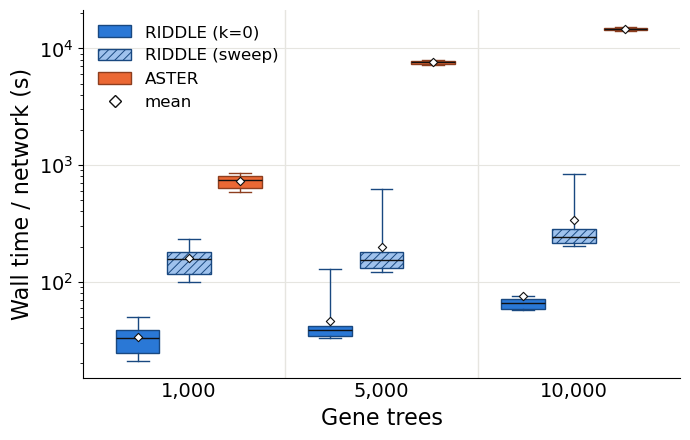

In [8]:
FIGSIZE = (7, 4.5)
LABEL_FS, TICK_FS, LEGEND_FS = 16, 14, 12
WHIS = (5, 95)
GROUP_W = 0.8           # the width one gene-tree count's boxes share
SHOW_POINTS = False     # every cell as a grey point (50 per box)
MEDIAN_LW = 1.0
# boxes outlined in a darker shade of their own colour: ASTRAL-IV's 5,000-tree box is thinner on the log axis than
# a median line, and a grey outline would leave it a black bar with no colour
OUTLINE = {m: tuple(DARK * np.array(mcolors.to_rgb(c)))
           for m, c in [("RIDDLE (k=0)", BLUE), ("RIDDLE (sweep)", BLUE), ("ASTER", ORANGE)]}
rng3 = np.random.default_rng(20261031)

step = GROUP_W / len(METHODS)
fig, ax = plt.subplots(figsize=FIGSIZE)
for x, size in enumerate(SIZES):
    for s, m in enumerate(METHODS):
        v = RT.loc[(RT["size"] == size) & (RT.method == m), "wall_s"].to_numpy()
        pos = x + (s - (len(METHODS) - 1) / 2) * step
        st = STYLE[m]
        bp = ax.boxplot([v], positions=[pos], widths=0.85 * step, whis=WHIS, patch_artist=True, showfliers=False,
                        medianprops=dict(color="#111111", lw=MEDIAN_LW),
                        whiskerprops=dict(color=OUTLINE[m], lw=1), capprops=dict(color=OUTLINE[m], lw=1))
        bp["boxes"][0].set(facecolor=st["face"], edgecolor=OUTLINE[m], linewidth=1, hatch=st["hatch"])
        if SHOW_POINTS:
            ax.scatter(pos + rng3.uniform(-0.25, 0.25, len(v)) * step, v, s=6, color=INK, alpha=0.4, lw=0, zorder=3)
        ax.scatter([pos], [v.mean()], marker="D", s=18, color="white", edgecolor="#111111", lw=0.8, zorder=4)

ax.set_yscale("log")
ax.set_xticks(range(len(SIZES)))
ax.set_xticklabels([SIZE_LABEL[s] for s in SIZES], fontsize=TICK_FS)
ax.tick_params(axis="x", length=0)
ax.set_xlim(-0.55, len(SIZES) - 0.45)
for x in range(len(SIZES) - 1):
    ax.axvline(x + 0.5, color=GRID, lw=1)
ax.set_xlabel("Gene trees", fontsize=LABEL_FS)
ax.set_ylabel("Wall time / network (s)", fontsize=LABEL_FS)
ax.tick_params(axis="y", labelsize=TICK_FS)
ax.grid(axis="y", which="major", color=GRID, lw=0.8)

handles = [Patch(facecolor=STYLE[m]["face"], edgecolor=OUTLINE[m], hatch=STYLE[m]["hatch"], label=m)
           for m in METHODS]
handles.append(Line2D([], [], marker="D", ls="", color="white", markeredgecolor="#111111", markersize=6, label="mean"))
ax.legend(handles=handles, loc="upper left", fontsize=LEGEND_FS, frameon=False)
fig.tight_layout()
fig.savefig(FIG_DIR / f"sptree-runtime-{TAG}.png", bbox_inches="tight", dpi=300)
plt.show()

In [9]:
# The numbers behind Figure 3, in seconds per network: per gene-tree count, method and cu ("all" is the pooled box
# drawn).
rows = []
for size in SIZES:
    for m in METHODS:
        for cu in CUS + ["all"]:
            v = RT.loc[(RT["size"] == size) & (RT.method == m) & ((RT.cu == cu) if cu != "all" else True), "wall_s"]
            rows.append({"gene trees": SIZE_LABEL[size], "method": m, "cu": cu, "cells": len(v),
                         "median": v.median(), "mean": v.mean(), "p5": v.quantile(0.05), "p95": v.quantile(0.95),
                         "max": v.max()})
with pd.option_context("display.max_rows", 100):
    display(pd.DataFrame(rows).set_index(["gene trees", "method", "cu"]).round(1))

# Medians over the 50 cells, and how many times faster RIDDLE is.  "sweep, k 0..10" is the whole sweep as run; the
# sweep drawn stops at k = 5, the last k its vote reads.
med = RT.groupby(["size", "method"]).wall_s.median().unstack("method").reindex(SIZES)
full = RT[RT.method == "RIDDLE (sweep)"].groupby("size").sweep_k10_s.median().reindex(SIZES)
a = med["ASTER"].to_numpy()
pd.DataFrame({"RIDDLE (k=0)": med["RIDDLE (k=0)"].to_numpy(), "RIDDLE (sweep)": med["RIDDLE (sweep)"].to_numpy(),
              "sweep, k 0..10": full.to_numpy(), "ASTRAL-IV": a,
              "ASTRAL-IV / RIDDLE (k=0)": a / med["RIDDLE (k=0)"].to_numpy(),
              "ASTRAL-IV / RIDDLE (sweep)": a / med["RIDDLE (sweep)"].to_numpy(),
              "ASTRAL-IV / sweep, k 0..10": a / full.to_numpy()},
             index=pd.Index([SIZE_LABEL[s] for s in SIZES], name="gene trees")).round(1)

cells   median     mean       p5      p95  \
gene trees method         cu                                                
1,000      RIDDLE (k=0)   0.1      20     38.4     41.4     33.1     57.7   
                          0.25     15     32.5     34.4     28.8     42.7   
                          0.5      15     23.1     22.8     19.2     25.4   
                          all      50     33.1     33.7     20.6     53.8   
           RIDDLE (sweep) 0.1      20    181.5    192.6    157.1    238.5   
                          0.25     15    157.7    163.5    133.9    205.3   
                          0.5      15    107.6    107.2     89.5    121.7   
                          all      50    158.0    158.3     96.2    231.6   
           ASTER          0.1      20    626.8    673.1    581.9    875.1   
                          0.25     15    793.6    798.7    768.9    843.5   
                          0.5      15    719.5    732.7    636.8    858.6   
                          all      50    749.5    728.7    583.1    860.5   
5,000      RIDDLE (k=0)   0.1      20     42.8     61.2     39.6    138.1   
                          0.25     15     38.3     38.1     35.5     40.4   
                          0.5      15     33.1     33.4     31.5     35.2   
                          all      50     38.5     45.9     32.7    131.2   
           RIDDLE (sweep) 0.1      20    183.9    285.0    161.6    716.4   
                          0.25     15    150.8    151.2    137.4    163.1   
                          0.5      15    126.2    126.2    117.9    136.2   
                          all      50    153.8    197.2    120.9    658.1   
           ASTER          0.1      20   7738.2   7736.6   7459.4   8041.9   
                          0.25     15   7514.3   7542.6   7288.5   7874.2   
                          0.5      15   7367.0   7435.1   6987.4   8034.3   
                          all      50   7581.9   7588.0   7177.9   8014.2   
10,000     RIDDLE (k=0)   0.1      20     71.4     99.2     67.3    258.8   
                          0.25     15     64.1     64.0     61.4     66.0   
                          0.5      15     57.2     57.4     55.3     59.7   
                          all      50     65.1     76.1     56.7    173.7   
           RIDDLE (sweep) 0.1      20    288.6    500.7    257.2   1367.3   
                          0.25     15    241.3    241.5    226.9    256.3   
                          0.5      15    208.8    208.3    196.3    221.5   
                          all      50    243.5    335.2    202.7    930.7   
           ASTER          0.1      20  14796.9  14800.2  14405.9  15348.7   
                          0.25     15  14464.6  14522.6  13988.7  15123.2   
                          0.5      15  14274.1  14447.1  13837.0  15508.5   
                          all      50  14553.5  14611.0  13946.6  15345.7   

                                    max  
gene trees method         cu             
1,000      RIDDLE (k=0)   0.1      59.9  
                          0.25     48.2  
                          0.5      27.9  
                          all      59.9  
           RIDDLE (sweep) 0.1     286.4  
                          0.25    230.5  
                          0.5     131.5  
                          all     286.4  
           ASTER          0.1     879.8  
                          0.25    847.7  
                          0.5     862.8  
                          all     879.8  
5,000      RIDDLE (k=0)   0.1     141.2  
                          0.25     41.7  
                          0.5      36.2  
                          all     141.2  
           RIDDLE (sweep) 0.1     729.7  
                          0.25    171.4  
                          0.5     141.8  
                          all     729.7  
           ASTER          0.1    8073.5  
                          0.25   7900.1  
                          0.5    8225.8  
                          all    8225.8  
10,000     RI

,RIDDLE (k=0),RIDDLE (sweep),"sweep, k 0..10",ASTRAL-IV,ASTRAL-IV / RIDDLE (k=0),ASTRAL-IV / RIDDLE (sweep),"ASTRAL-IV / sweep, k 0..10"
gene trees,,,,,,,
"1,000",33.1,158.0,285.3,749.5,22.7,4.7,2.6
"5,000",38.5,153.8,271.7,7581.9,197.2,49.3,27.9
"10,000",65.1,243.5,429.5,14553.5,223.6,59.8,33.9


## The sweep: what the vote keeps

Per gene-tree count and cu:
- **kept = r**: the number of cells whose sweep kept r reticulations (`n_kept`).
- **candidates**: the mean number of distinct signatures over k = 1..5 (`n_cand`).
- **clusters added**: the mean number of clusters the kept signatures add to RIDDLE's k = 0 tree (`n_added`).
- **ΔF1** and **ΔRF**: the sweep minus RIDDLE (k=0), as a mean over cells.

Against a tree truth, every kept reticulation is a false positive.

In [10]:
SW = HEAD[HEAD.method == "RIDDLE (sweep)"].set_index(["size", "rep"])
K0 = HEAD[HEAD.method == "RIDDLE (k=0)"].set_index(["size", "rep"])
rows = []
for size in SIZES:
    for cu in CUS + ["all"]:
        S = SW.loc[size]
        S = S[S.cu == cu] if cu != "all" else S
        Z = K0.loc[size].loc[S.index]
        row = {"gene trees": SIZE_LABEL[size], "cu": cu, "cells": len(S)}
        row.update({f"kept = {r}": int((S.n_kept == r).sum()) for r in range(0, int(SW.n_kept.max()) + 1)})
        row.update({"candidates": S.n_cand.mean(), "clusters added": S.n_added.mean(),
                    "ΔF1": (S.f1 - Z.f1).mean(), "ΔRF": (S.rf_hw_norm - Z.rf_hw_norm).mean()})
        rows.append(row)
pd.DataFrame(rows).set_index(["gene trees", "cu"]).round(4)

cells  kept = 0  kept = 1  kept = 2  kept = 3  kept = 4  \
gene trees cu                                                              
1,000      0.1      20         0         1         7        11         1   
           0.25     15         0         2         6         7         0   
           0.5      15         0         0         3        10         2   
           all      50         0         3        16        28         3   
5,000      0.1      20         0         0         8        10         2   
           0.25     15         0         1         2        12         0   
           0.5      15         0         0         4        11         0   
           all      50         0         1        14        33         2   
10,000     0.1      20         0         1         2        14         3   
           0.25     15         0         2         5         8         0   
           0.5      15         0         0         7         8         0   
           all      50         0         3        14        30         3   

                 candidates  clusters added     ΔF1     ΔRF  
gene trees cu                                                
1,000      0.1       6.3500          2.7000 -0.0035  0.0043  
           0.25      7.1333          2.5333 -0.0024  0.0027  
           0.5       5.7333          3.0000 -0.0027  0.0029  
           all       6.4000          2.7400 -0.0030  0.0034  
5,000      0.1       6.6000          2.7500 -0.0041  0.0047  
           0.25      6.3333          3.0000 -0.0043  0.0046  
           0.5       6.0667          3.0000 -0.0054  0.0056  
           all       6.3600          2.9000 -0.0046  0.0049  
10,000     0.1       6.1000          3.0000 -0.0050  0.0056  
           0.25      5.9333          2.4667 -0.0040  0.0042  
           0.5       6.1333          2.8000 -0.0043  0.0044  
           all       6.0600          2.7800 -0.0045  0.0048